In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
adata=sc.read_h5ad('/home/julia/data/placodes/h5ad/E9_E10_E11_UMAP.h5ad')

In [4]:
adata

AnnData object with n_obs × n_vars = 94890 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

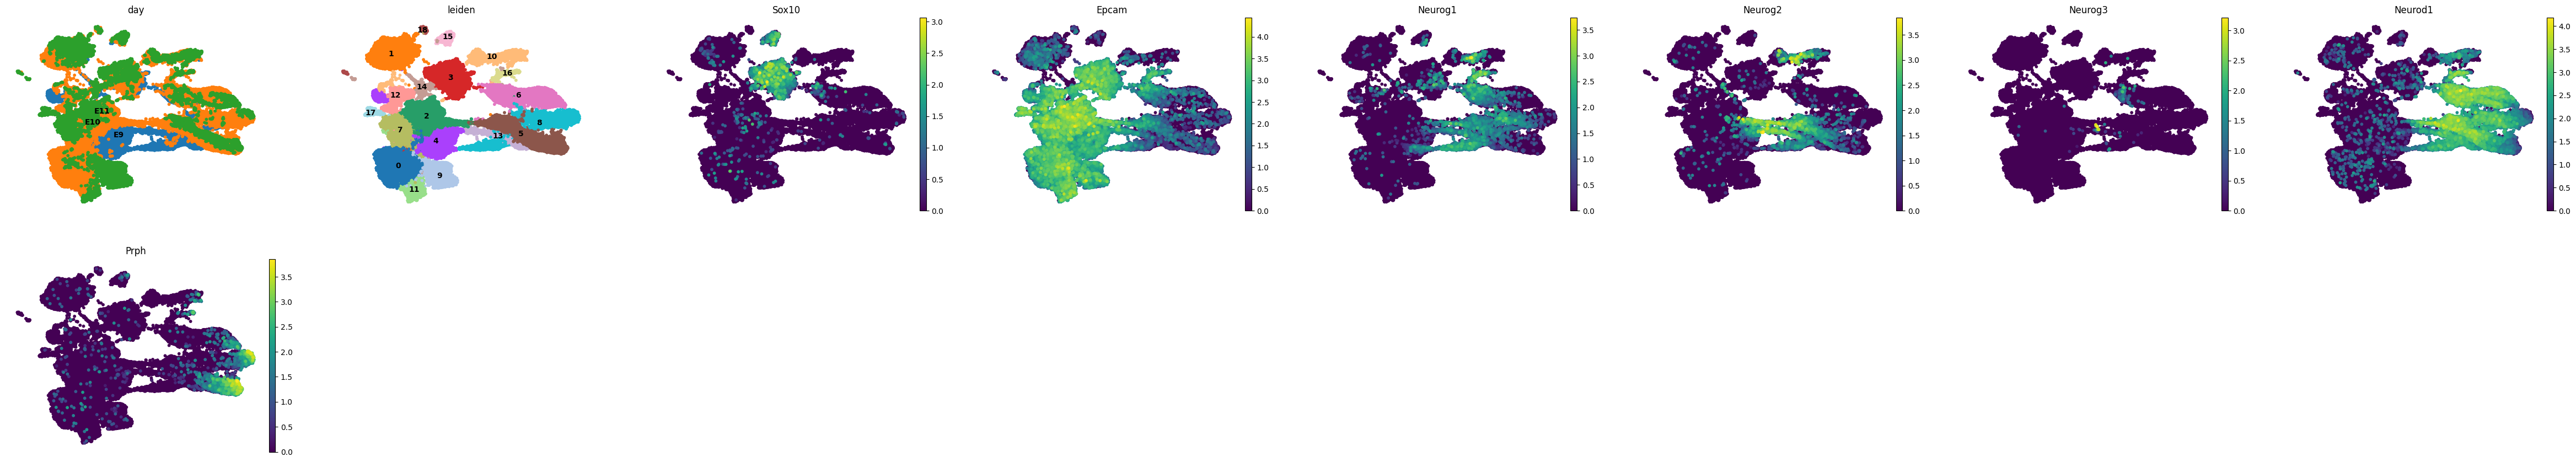

In [5]:
sc.pl.umap(adata, color=["day", "leiden", 'Sox10', 'Epcam', 'Neurog1','Neurog2', 'Neurog3', 'Neurod1', 'Prph'], frameon=False, size=70, legend_loc='on data', ncols=8)

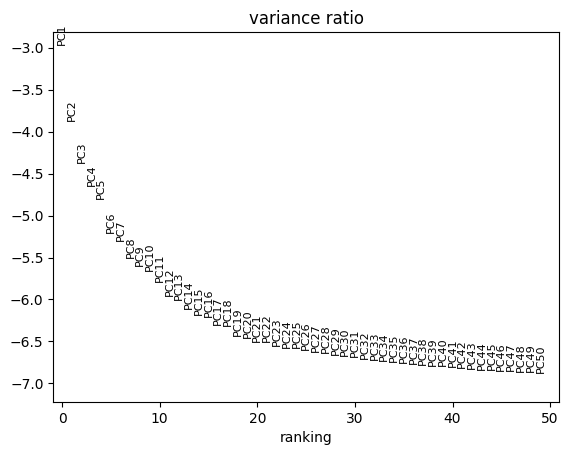

In [6]:
CLUSTERS = [ "6"]   # ← ваши кластеры
sub = adata[adata.obs["leiden"].isin(CLUSTERS)].copy()
sub.obs["leiden_parent"] = sub.obs["leiden"].astype(str)
#sc.pp.filter_genes(sub, min_cells=5)

sub.X = sub.layers["counts"].copy()
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sub.layers["lognorm"] = sub.X.copy()
sc.pp.highly_variable_genes(sub, flavor="seurat_v3", layer="counts",  n_top_genes=3000, batch_key="day")

# скейлинг + PCA во временной копии
tmp = sub[:, sub.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)

sub.obsm["X_pca"] = tmp.obsm["X_pca"]
sub.uns["pca"] = tmp.uns["pca"]
del tmp

/tmp/ipykernel_1497371/2608775648.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(sub, resolution=0.7, key_added="leiden_sub")


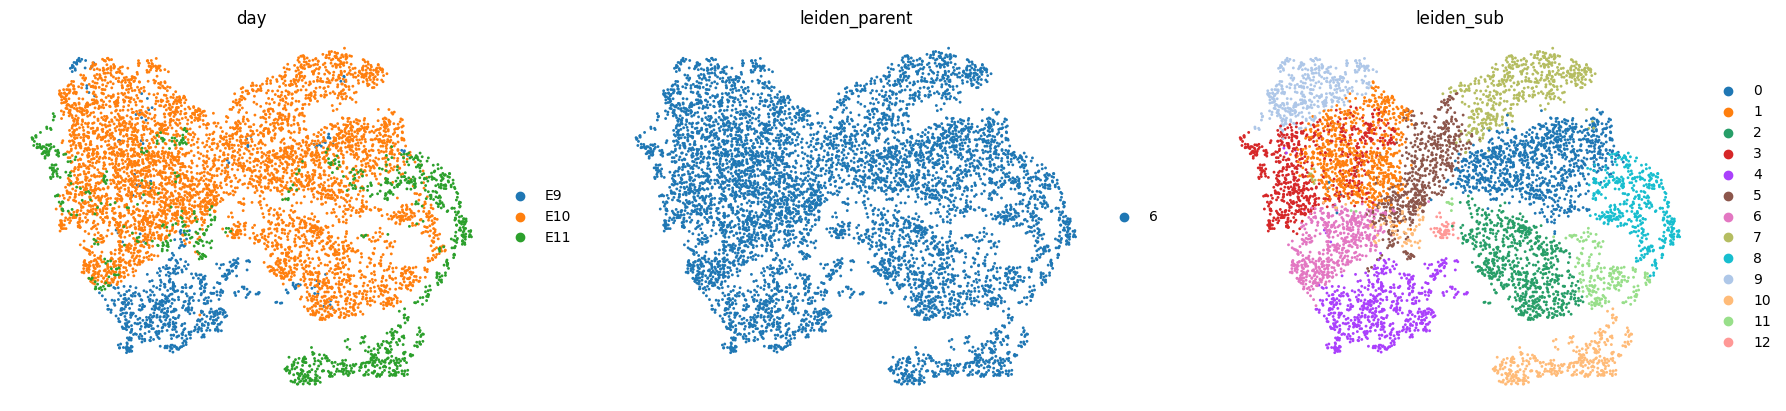

In [7]:
sc.pp.neighbors(sub, n_pcs=45, n_neighbors=45)   # n_pcs по графику локтя
sc.tl.leiden(sub, resolution=0.7, key_added="leiden_sub")
sc.tl.umap(sub, min_dist=0.6)
sc.pl.umap(sub, color=["day", "leiden_parent", "leiden_sub"], frameon=False)

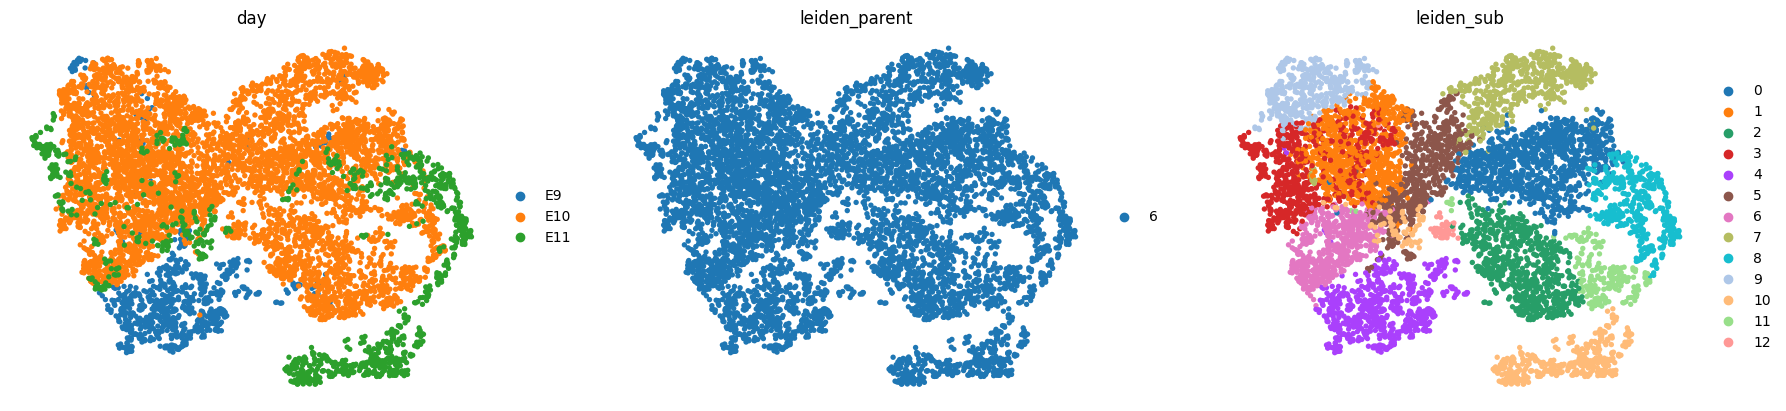

In [23]:
sc.pl.umap(sub, color=["day", "leiden_parent", "leiden_sub"], frameon=False, size=60)

In [9]:
sub.write_h5ad('sub_cl6.h5ad')

In [12]:
pwd

'/home/julia/Placodes_SUB/Sub_3_10_16'

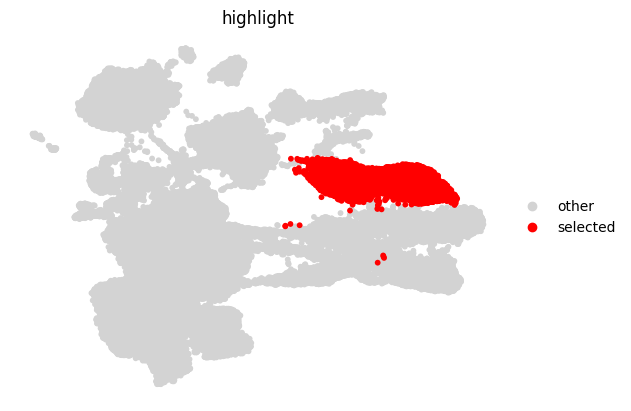

In [11]:
# take cells from your final subset
cells_of_interest = sub.obs_names   # change sub3 to your final subset object

# create a label in the original adata
adata.obs["highlight"] = "other"
adata.obs.loc[cells_of_interest, "highlight"] = "selected"

# plot selected cells on top
idx_other = np.where(adata.obs["highlight"] == "other")[0]
idx_sel   = np.where(adata.obs["highlight"] == "selected")[0]
idx = np.concatenate([idx_other, idx_sel])

sc.pl.umap(
    adata[idx].copy(),
    color="highlight",
    palette={"other": "lightgrey", "selected": "red"},
    size=70,
    frameon=False,
    legend_loc="right margin", save='sub_cl.pdf'
)

/home/julia/miniconda3/envs/Scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:471: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


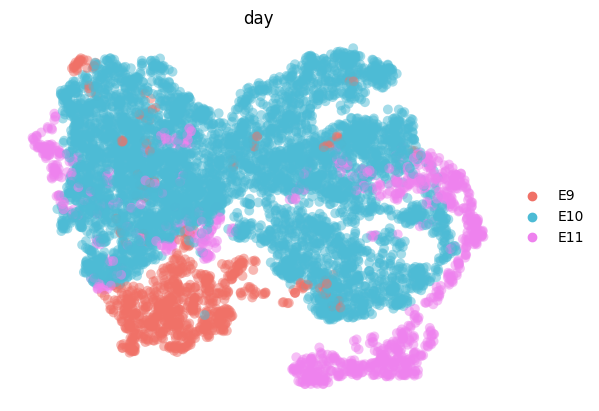

In [21]:
import numpy as np

# shuffle cell order so neither day sits on top
np.random.seed(0)
idx = np.random.permutation(sub.n_obs)

sc.pl.umap(
    sub[idx],
    color="day",
    palette={"E9": "#F07167","E11": "violet", "E10": "#4DBBD5"},
    size=200,
    frameon=False,
    legend_loc="right margin",alpha=0.5,
 save="sub_day_e10_11__11.pdf",
)

In [22]:
sub

AnnData object with n_obs × n_vars = 7153 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'leiden_sub', 'leiden_parent_colors', 'leiden_sub_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'lognorm'
    obsp: 'connectivities', 'distances'